# Session 6 — From a Linear Model to a Neural Network

Sessions 0 to 5 used models from scikit-learn, and logistic regression came up more than once. A neural network is built from the same part: multiply the inputs by weights, add a bias, and pass the result through a function. The difference is that a network stacks these units in layers. This session shows what that stacking buys, using the smallest problem where it matters, and then opens up the step every earlier session hid inside `fit`: how a model's weights are actually learned.

From this session on, the course builds its networks with **PyTorch**, a widely used library for neural networks. It shows the training loop in plain code instead of hiding it.

**By the end of the session you should be able to:**

1. explain why a straight-line model can't solve XOR, and why layers need a non-linear step between them;
2. write the loop that trains a model: compute the loss, compute its gradient, take a small step;
3. build and train a small network in PyTorch, count its parameters and read its decision boundary.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib`, `scikit-learn` and `torch` (see the course README). The outputs are already saved in the notebook. It runs in a few seconds on a CPU, and your numbers may differ slightly from the ones quoted in the text.

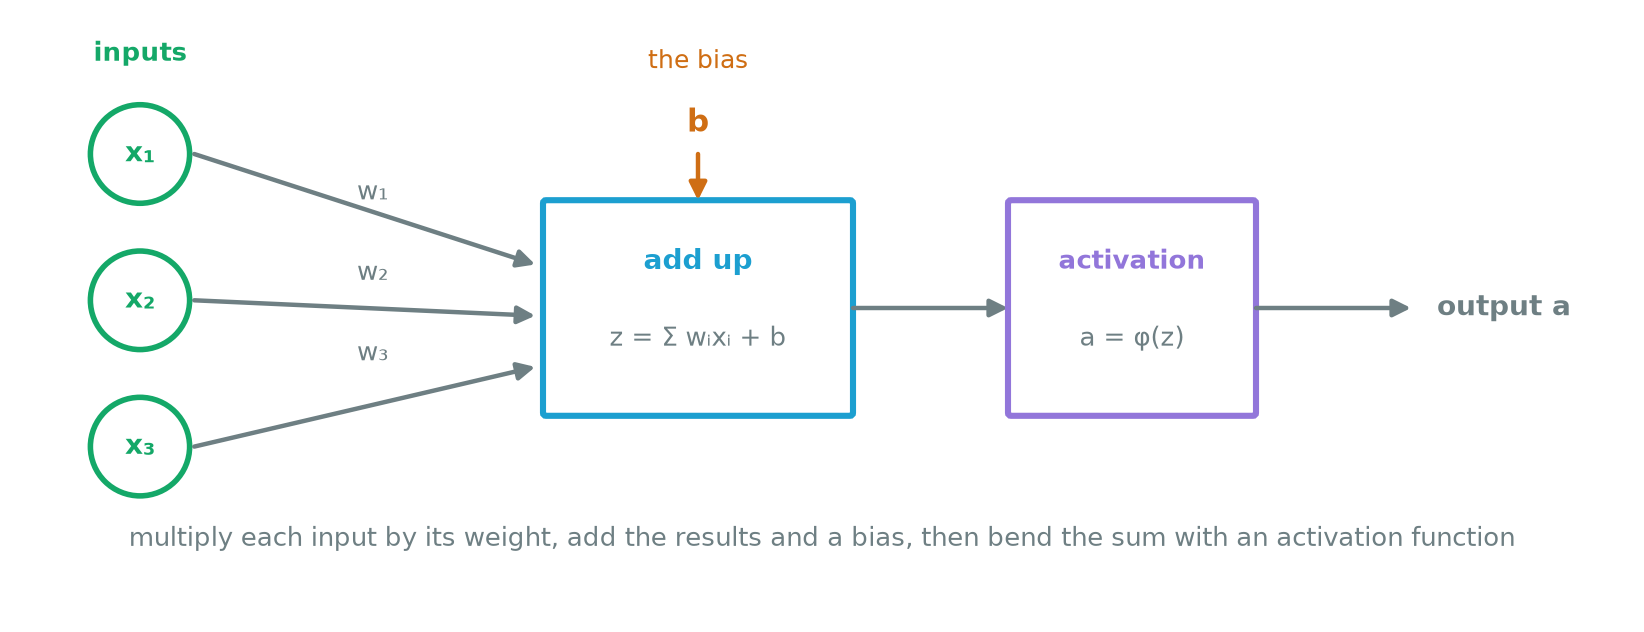

*Figure 6.1 — One unit. Each input is multiplied by its own weight, the products are added together with a bias, and an activation function turns the sum into the unit's output. Logistic regression is one such unit with a sigmoid activation.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression

SEED = 42
X_xor = np.array([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
y_xor = np.array([0, 1, 1, 0])

linear = LogisticRegression().fit(X_xor, y_xor)
pd.DataFrame({"x1": X_xor[:, 0], "x2": X_xor[:, 1], "target": y_xor, "logistic regression": linear.predict(X_xor)})

,x1,x2,target,logistic regression
0,0.0,0.0,0,0
1,0.0,1.0,1,0
2,1.0,0.0,1,0
3,1.0,1.0,0,0


## 1. A problem a straight line can't solve

XOR ("exclusive or") has two inputs that are each 0 or 1, and the answer is 1 when exactly one of them is 1:

| x1 | x2 | answer |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

> **Pause:** look at the four corners of the square. Can you draw one straight line with both 1s on one side and both 0s on the other?
>
> - **A.** Yes, with a tilted line.
> - **B.** No: no straight line separates them.
> - **C.** Yes, once the model gets a bias term.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**B.** No straight line works (this is XOR). Logistic regression predicts 0.5 at all four corners and scores an accuracy of 0.5.

</details>

We give the four rows to a logistic regression. It predicts 0 for every row, so it scores 0.5.

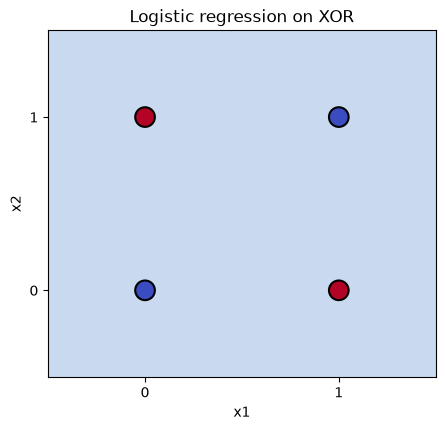

Accuracy: 0.5
Predicted probabilities: [0.5 0.5 0.5 0.5]


In [2]:
grid_x, grid_y = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
grid = np.c_[grid_x.ravel(), grid_y.ravel()]


def show_boundary(ax, predict, title):
    ax.contourf(grid_x, grid_y, predict(grid).reshape(grid_x.shape), levels=[0, 0.5, 1], colors=["#c9daf0", "#f6cfc4"])
    ax.scatter(*X_xor.T, c=y_xor, cmap="coolwarm", s=200, edgecolor="k", linewidth=1.5)
    ax.set(title=title, xlabel="x1", ylabel="x2", xticks=[0, 1], yticks=[0, 1])


fig, ax = plt.subplots(figsize=(5, 4.5))
show_boundary(ax, lambda g: linear.predict_proba(g)[:, 1], "Logistic regression on XOR")
plt.show()
print("Accuracy:", linear.score(X_xor, y_xor))
print("Predicted probabilities:", linear.predict_proba(X_xor)[:, 1].round(2))

The plot shades the plane by the model's prediction. It is one flat colour: the four points are arranged so that no direction in the plane helps, and the model's probability is 0.50 at all four corners. Training for longer would change nothing, since the limit comes from the shape of the model (a straight boundary), not from how well it was fitted.

This limit shaped the history of the field. In 1958 Frank Rosenblatt described the **perceptron**, a single unit that learns its weights from examples and, like logistic regression, draws a straight boundary. In 1969 Marvin Minsky and Seymour Papert's book *Perceptrons* showed that such a unit cannot compute XOR, and interest in neural networks dropped for years. The answer, layers of units with a way to train them, is the rest of this session.

In [3]:
rng = np.random.default_rng(0)
W1, b1 = rng.normal(size=(3, 2)), rng.normal(size=3)
W2, b2 = rng.normal(size=(1, 3)), rng.normal(size=1)

x = rng.normal(size=2)
two_layers = W2 @ (W1 @ x + b1) + b2
one_layer = (W2 @ W1) @ x + (W2 @ b1 + b2)
print("Two linear layers: ", two_layers)
print("One merged layer:  ", one_layer)
print("Merged weights:", (W2 @ W1).round(3), " merged bias:", (W2 @ b1 + b2).round(3))

Two linear layers:  [-4.61296337]
One merged layer:   [-4.61296337]
Merged weights: [[-0.58   0.117]]  merged bias: [-4.595]


## 2. Why layers need a non-linear step

The fix is to put another layer in between. A first guess might be to chain two linear layers, where the first turns the inputs into three new numbers and the second turns those into the answer.

> **Pause:** does the chain of two linear layers have more power than one?
>
> - **A.** Yes: two layers can bend the boundary.
> - **B.** Yes, but only if each layer is wide.
> - **C.** No: two linear layers collapse into one linear layer.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**C.** The two layers and one merged layer give the same output, -4.61296337. The merged weights are W₂W₁ and the bias is W₂b₁ + b₂, so a straight boundary stays straight.

</details>

The cell builds random weights for two layers and passes one input through them, then through one single layer with merged weights. Both give −4.613. Written out, the first layer computes $h=W_1x+b_1$ and the second computes $y=W_2h+b_2$. Substituting,

$$
y=W_2(W_1x+b_1)+b_2=(W_2W_1)\,x+(W_2b_1+b_2),
$$

which is a single linear layer with weights $W_2W_1$ and bias $W_2b_1+b_2$. The merged weights printed in the cell are those products. A hundred stacked linear layers would also collapse into one, and a straight boundary stays straight.

To get more than a line, each layer must be followed by a non-linear function. This function is called the **activation**.

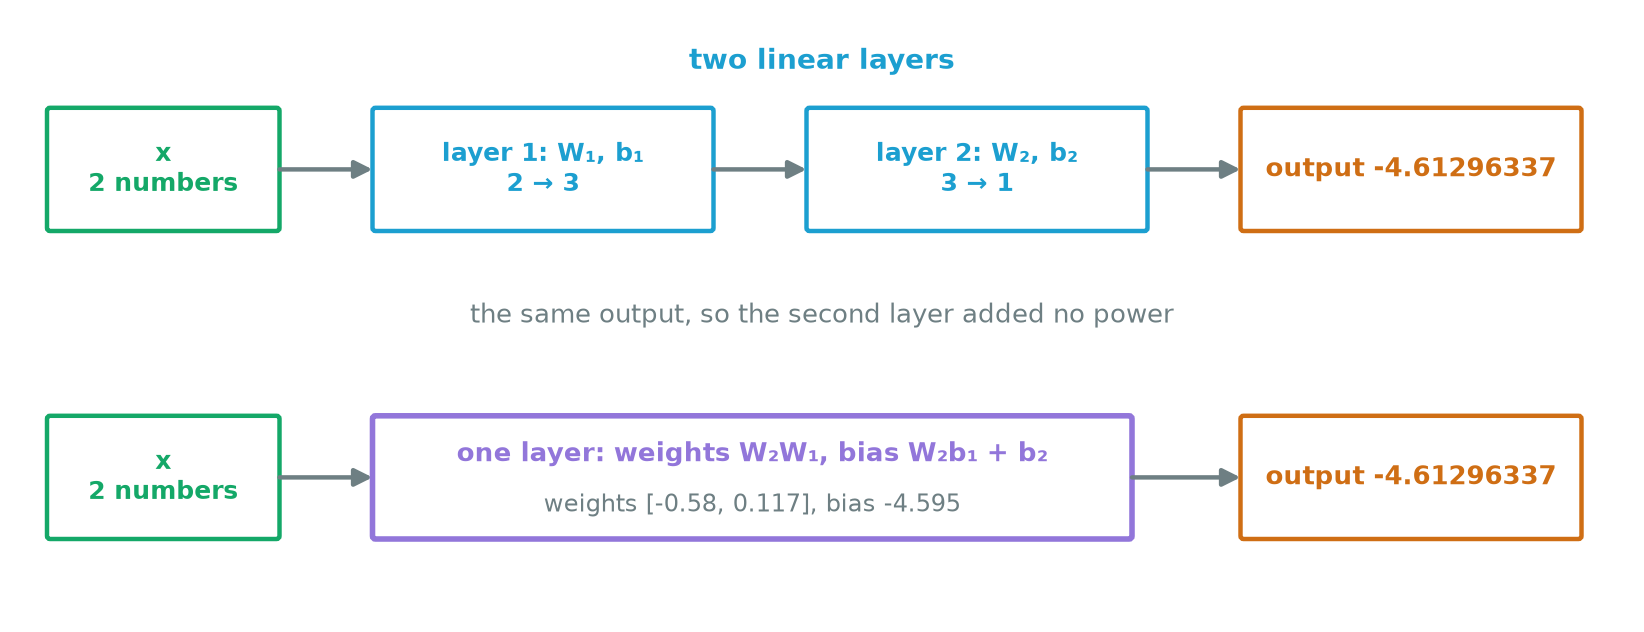

*Figure 6.2 — Two linear layers collapse into one. The chain W₁ then W₂ gives the same output (-4.61296337) as a single layer with weights W₂W₁ and bias W₂b₁ + b₂, so a straight boundary stays straight.*

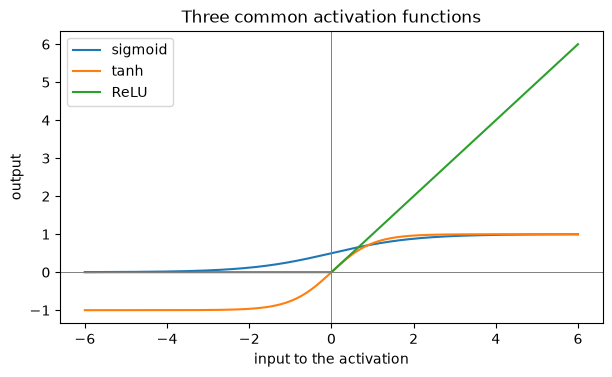

In [4]:
z = np.linspace(-6, 6, 300)
plt.figure(figsize=(7, 3.8))
plt.plot(z, 1 / (1 + np.exp(-z)), label="sigmoid")
plt.plot(z, np.tanh(z), label="tanh")
plt.plot(z, np.maximum(0, z), label="ReLU")
plt.axhline(0, color="grey", linewidth=0.7)
plt.axvline(0, color="grey", linewidth=0.7)
plt.xlabel("input to the activation")
plt.ylabel("output")
plt.title("Three common activation functions")
plt.legend()
plt.show()

The plot shows three common choices. **Sigmoid** squeezes any number into the range 0 to 1. **tanh** squeezes it into −1 to 1. **ReLU** returns 0 for negative inputs and passes positive ones through unchanged. Each one bends the straight line of a single unit, and that bend is what stops the layers from merging. The formulas are in Going deeper. Hidden layers today usually use ReLU, and a binary output uses sigmoid so that it can be read as a probability.

In [5]:
at_least_one = (X_xor.sum(axis=1) >= 1).astype(int)
both = (X_xor.sum(axis=1) >= 2).astype(int)
pd.DataFrame({"x1": X_xor[:, 0], "x2": X_xor[:, 1], "hidden 1: at least one": at_least_one, "hidden 2: both": both, "output = h1 - h2": at_least_one - both})

,x1,x2,hidden 1: at least one,hidden 2: both,output = h1 - h2
0,0.0,0.0,0,0,0
1,0.0,1.0,1,0,1
2,1.0,0.0,1,0,1
3,1.0,1.0,1,1,0


## 3. Solving XOR by hand with two hidden units

We can build a solution ourselves with two hidden units that ask simple questions:

- hidden unit 1: is **at least one** input on?
- hidden unit 2: are **both** inputs on?

The output is the first answer minus the second: on if at least one input is on, unless both are. The table shows this reproduces XOR exactly.

Each hidden unit by itself draws a straight line. The output layer combines the two answers, and the combination is not a straight line in the original inputs. This is what hidden layers do: they turn the inputs into new features that make the final decision easy. In a real network we don't write these features. Training finds them.

In [6]:
# Versicolor (0) and virginica (1), the two species Session 0's model mixed up, described by two petal measurements
iris = load_iris(as_frame=True)
flowers = iris.target > 0
X_iris = iris.data.loc[flowers, ["petal length (cm)", "petal width (cm)"]].to_numpy()
y_iris = (iris.target[flowers] == 2).to_numpy().astype(float)
X_std = (X_iris - X_iris.mean(axis=0)) / X_iris.std(axis=0)  # rescaled as in Session 2, so that one step size suits both features


def predict_probability(X, w, b):
    return 1 / (1 + np.exp(-(X @ w + b)))  # one unit: weighted sum, then sigmoid


def loss_and_gradient(X, y, w, b):
    p = predict_probability(X, w, b)
    loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))  # binary cross-entropy
    return loss, X.T @ (p - y) / len(y), np.mean(p - y)  # the loss, and how it changes with each weight and with the bias


w_start, b_start, learning_rate = np.array([1.5, -1.5]), 0.0, 1.0  # a deliberately poor first guess
w, b = w_start, b_start
losses, snapshots = [], {0: (w, b)}
print(f"{len(y_iris)} flowers. Start: accuracy {((predict_probability(X_std, w, b) > 0.5) == y_iris).mean():.2f}")
for step in range(1, 101):
    loss, grad_w, grad_b = loss_and_gradient(X_std, y_iris, w, b)
    w, b = w - learning_rate * grad_w, b - learning_rate * grad_b  # a small step downhill
    losses.append(loss)
    snapshots[step] = (w, b)
    if step in (1, 3, 10, 30, 100):
        accuracy = ((predict_probability(X_std, w, b) > 0.5) == y_iris).mean()
        print(f"step {step:3d}: loss {loss:.3f} before the step; after it, weights {w.round(2)}, bias {b:.2f}, accuracy {accuracy:.2f}")

100 flowers. Start: accuracy 0.39
step   1: loss 0.815 before the step; after it, weights [ 1.84 -1.03], bias 0.00, accuracy 0.69
step   3: loss 0.413 before the step; after it, weights [ 2.19 -0.47], bias 0.03, accuracy 0.85
step  10: loss 0.215 before the step; after it, weights [2.65 0.4 ], bias 0.06, accuracy 0.95
step  30: loss 0.145 before the step; after it, weights [3.12 1.39], bias 0.11, accuracy 0.95
step 100: loss 0.113 before the step; after it, weights [3.67 2.67], bias 0.24, accuracy 0.94


## 4. How a model learns: a loss, a gradient and a small step

Every `fit` so far has hidden one loop. Here it is written out for the simplest model, a single sigmoid unit (logistic regression), on the two species that Session 0's model confused: versicolor and virginica, described by petal length and petal width.

Three ideas carry the whole loop:

- The **loss** is one number that says how wrong the model is on the training data. Here it is the **binary cross-entropy**: for each flower, take the probability the model gave to the right species, take minus its logarithm, and average. A confident right answer costs almost nothing; a confident wrong answer costs a lot.
- The **gradient** says, for each weight, how fast the loss rises when that weight is nudged up. For this model it has a short formula, `X.T @ (p - y) / n` (derived in Going deeper).
- The **learning rate** is the size of the step. Each step moves every weight a little against its gradient, `w = w - learning_rate * grad_w`, which lowers the loss. This is **gradient descent**.

An **epoch** is one pass through the training data. This loop uses all the flowers in every step, so each step here is one epoch; Session 7 splits an epoch into smaller batches.

The loop starts from a deliberately poor guess, weights [1.5, −1.5], which gets only 0.39 of the flowers right. Each printed line is one step.

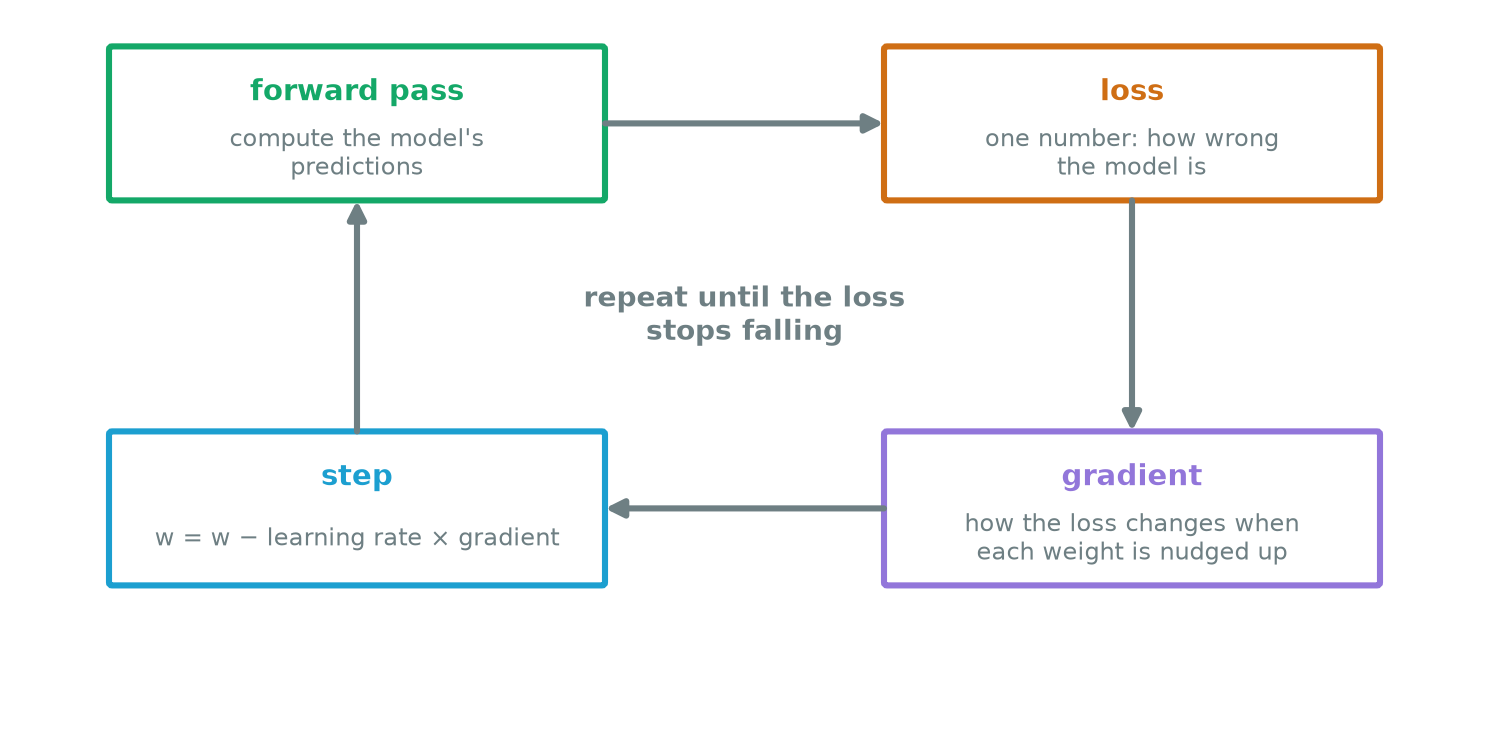

*Figure 6.3 — The training loop that every fit hides. Compute predictions, measure the loss, compute the gradient of the loss with respect to each weight, take a small step against it, and go round again.*

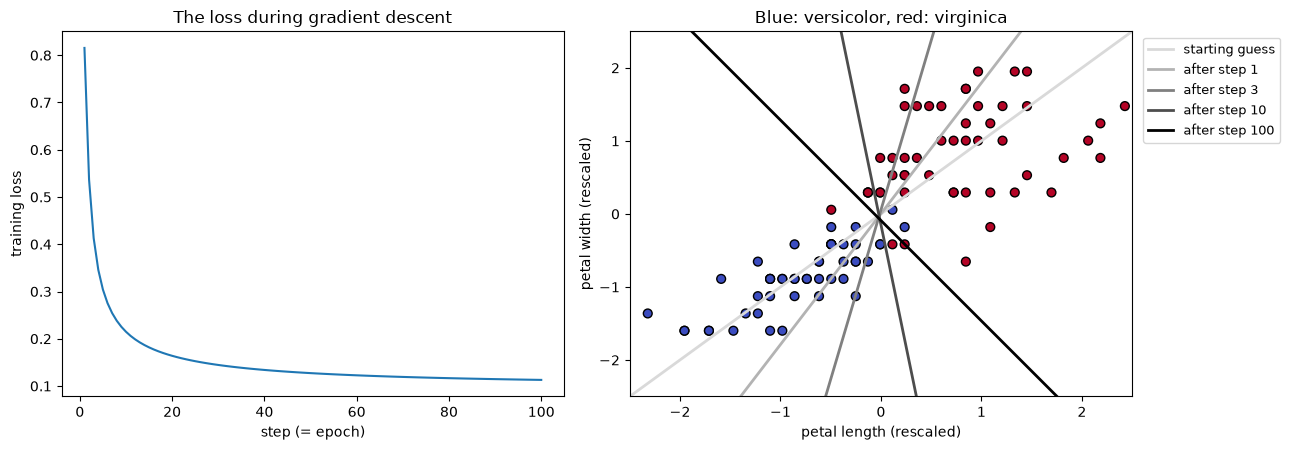

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(range(1, 101), losses)
axes[0].set(xlabel="step (= epoch)", ylabel="training loss", title="The loss during gradient descent")
axes[1].scatter(*X_std.T, c=y_iris, cmap="coolwarm", edgecolor="k", s=40)
line_x = np.linspace(-2.5, 2.5, 50)
for step, shade in zip([0, 1, 3, 10, 100], ["0.85", "0.7", "0.5", "0.3", "0"]):
    (w0, w1), b0 = snapshots[step]
    axes[1].plot(line_x, -(w0 * line_x + b0) / w1, color=shade, lw=2, label="starting guess" if step == 0 else f"after step {step}")
axes[1].set(xlim=(-2.5, 2.5), ylim=(-2.5, 2.5), xlabel="petal length (rescaled)", ylabel="petal width (rescaled)", title="Blue: versicolor, red: virginica")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout()
plt.show()

The loss falls fast at first and then slowly: 0.815 before the first step, 0.413 before step 3, 0.215 before step 10 and 0.113 before step 100. Training accuracy goes from 0.39 at the start to 0.69 after one step, 0.85 after three and 0.95 after ten, and ends at 0.94.

The right-hand plot shows what the steps do. The starting boundary (the lightest line) runs along the cloud of flowers and cuts both species in half. Each step turns it, and after 10 steps it crosses the cloud between the blue and the red flowers. From step 10 to step 100 the line turns further, but few flowers change side. The weights keep growing, from [2.65, 0.4] to [3.67, 2.67], which makes the model more confident and lowers the loss further. Six flowers stay on the wrong side because the two species overlap, as Session 0 found.

Nothing in the loop knows about flowers. It only follows the gradient downhill.

In [8]:
# The same loss built from PyTorch tensors. requires_grad=True tells PyTorch to record every operation on these numbers.
w_t = torch.tensor(w_start, requires_grad=True)  # the starting guess from the loop above
b_t = torch.tensor(b_start, dtype=torch.float64, requires_grad=True)
X_t, y_t = torch.tensor(X_std), torch.tensor(y_iris)
p_t = torch.sigmoid(X_t @ w_t + b_t)
loss_t = -(y_t * torch.log(p_t) + (1 - y_t) * torch.log(1 - p_t)).mean()
loss_t.backward()  # backpropagation: fills in w_t.grad and b_t.grad

_, grad_w, grad_b = loss_and_gradient(X_std, y_iris, w_start, b_start)  # the hand-written formula at the same point
print(f"gradient by hand:   weights {grad_w.round(6)}, bias {grad_b:.6f}")
print(f"gradient, autograd: weights {w_t.grad.numpy().round(6)}, bias {b_t.grad.item():.6f}")

gradient by hand:   weights [-0.34001  -0.473045], bias -0.002774
gradient, autograd: weights [-0.34001  -0.473045], bias -0.002774


Writing the gradient by hand works for one unit. For a network with many layers and millions of weights, nobody writes it out. **Backpropagation** computes it automatically: it goes backwards through the calculation, layer by layer, applying the chain rule from calculus. PyTorch does this when you call `loss.backward()` on a loss built from tensors marked `requires_grad=True`. This is called **autograd**.

The cell builds the same loss at the same starting guess. Both ways give the same gradient: [−0.34001, −0.473045] for the weights and −0.002774 for the bias. The minus signs say that raising either weight lowers the loss, which is why the first step raised both weights, from [1.5, −1.5] to [1.84, −1.03].

Backpropagation was popularised in 1986 by David Rumelhart, Geoffrey Hinton and Ronald Williams, and it made networks with hidden layers trainable: the answer to the perceptron's limit in section 1. Every network in the rest of this course is trained with this loop: forward pass, loss, `backward`, step.

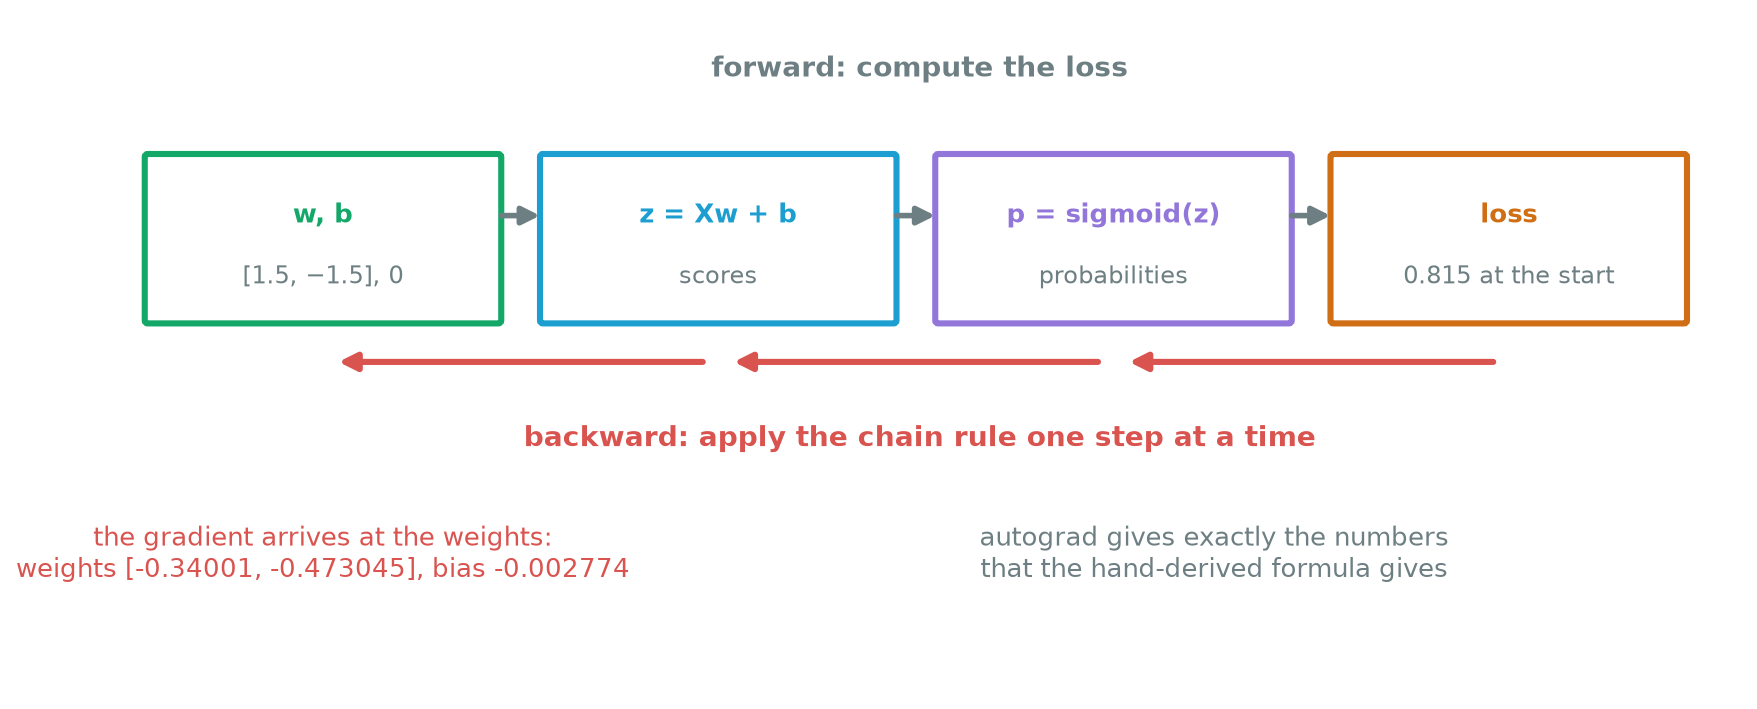

*Figure 6.4 — Backpropagation on the one-unit model. Forward, the loss is computed from the weights through the scores and the probabilities. Backward, the chain rule carries the gradient from the loss back to the weights: [-0.34001, -0.473045] for the weights and -0.002774 for the bias, the same numbers as the formula by hand.*

In [9]:
torch.manual_seed(SEED)
xor_model = nn.Sequential(nn.Linear(2, 4), nn.Tanh(), nn.Linear(4, 1), nn.Sigmoid())
optimizer = torch.optim.Adam(xor_model.parameters(), lr=0.05)
loss_fn = nn.BCELoss()  # binary cross-entropy, as in section 4
X_xor_t = torch.tensor(X_xor, dtype=torch.float32)
y_xor_t = torch.tensor(y_xor, dtype=torch.float32).unsqueeze(1)

history = []
for epoch in range(500):
    loss = loss_fn(xor_model(X_xor_t), y_xor_t)  # forward pass and loss
    optimizer.zero_grad()  # clear the previous step's gradients
    loss.backward()  # backpropagation
    optimizer.step()  # move every weight a small step
    history.append(loss.item())

print(xor_model)
for name, weights in xor_model.named_parameters():
    print(f"  {name:9s} shape {str(tuple(weights.shape)):7s} -> {weights.numel()}")
print("Total parameters:", sum(weights.numel() for weights in xor_model.parameters()))
with torch.no_grad():
    probabilities = xor_model(X_xor_t).numpy().ravel()
pd.DataFrame({"x1": X_xor[:, 0], "x2": X_xor[:, 1], "target": y_xor, "probability": probabilities.round(3), "prediction": (probabilities >= 0.5).astype(int)})

Sequential(
  (0): Linear(in_features=2, out_features=4, bias=True)
  (1): Tanh()
  (2): Linear(in_features=4, out_features=1, bias=True)
  (3): Sigmoid()
)
  0.weight  shape (4, 2)  -> 8
  0.bias    shape (4,)    -> 4
  2.weight  shape (1, 4)  -> 4
  2.bias    shape (1,)    -> 1
Total parameters: 17


,x1,x2,target,probability,prediction
0,0.0,0.0,0,0.000,0
1,0.0,1.0,1,0.998,1
2,1.0,0.0,1,0.998,1
3,1.0,1.0,0,0.004,0


## 5. A network that learns XOR

Now the network from section 3, with features learned instead of written by hand: two inputs, a hidden layer of four `tanh` units and one sigmoid output. `nn.Sequential` chains the layers in order, and `nn.Linear(2, 4)` is a layer of four units with two inputs each.

The training loop is the one from section 4 with two jobs handed to PyTorch. `loss.backward()` computes the gradients, and the **optimiser** takes the step. We use **Adam**, a refinement of the plain step that adapts the step size for each weight; it is the usual default (Going deeper describes it). `optimizer.zero_grad()` clears the previous step's gradients, which PyTorch would otherwise add up. We train for 500 epochs, each a pass over the four rows.

The parameter list shows where the 17 numbers are: the hidden layer has a 4 × 2 weight matrix and 4 biases (12), and the output layer has 4 weights and 1 bias (5). The predictions are 0.000 and 0.004 for the two 0 rows, and 0.998 for both 1 rows. All four are right and confident.

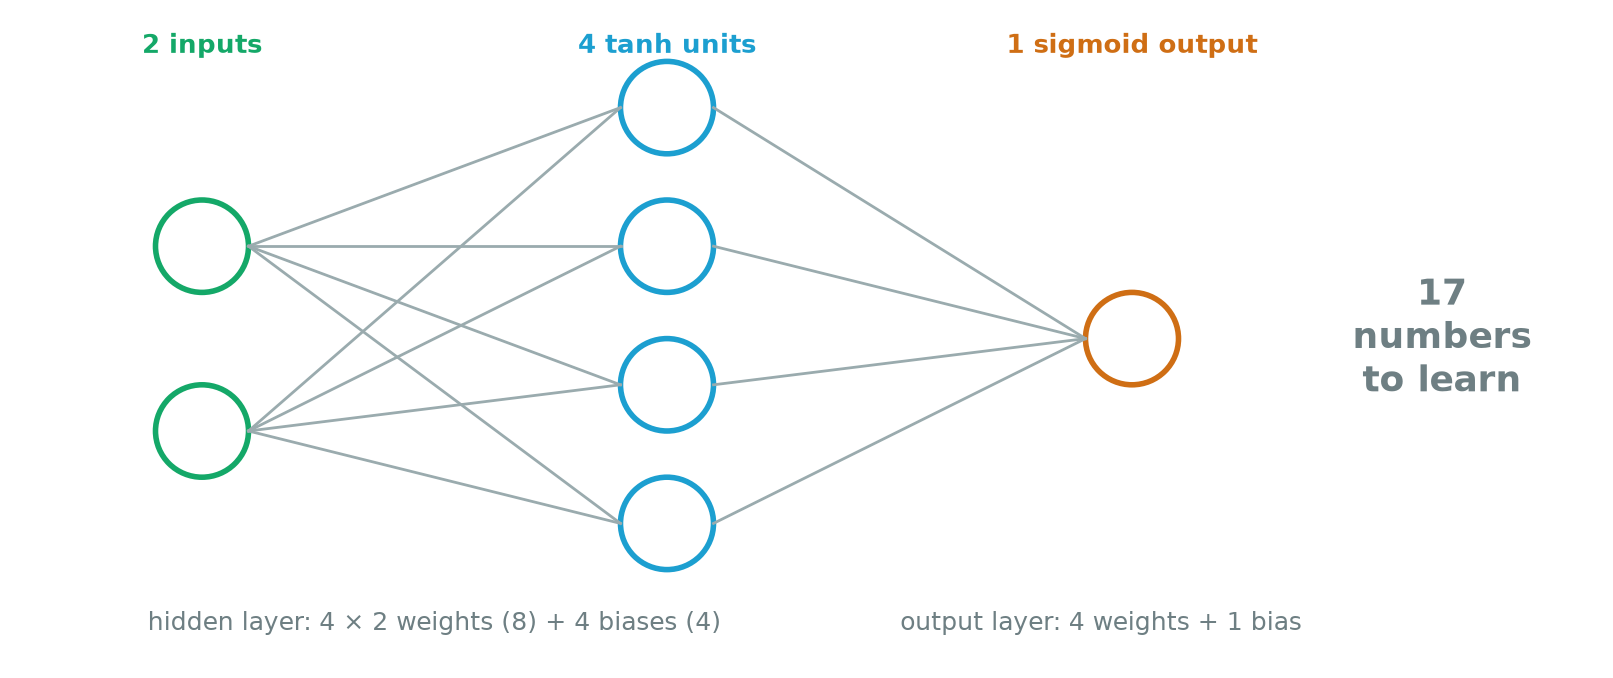

*Figure 6.5 — The network that learns XOR: two inputs, four tanh units and one sigmoid output. Counting the weights and biases layer by layer gives 17 numbers to learn.*

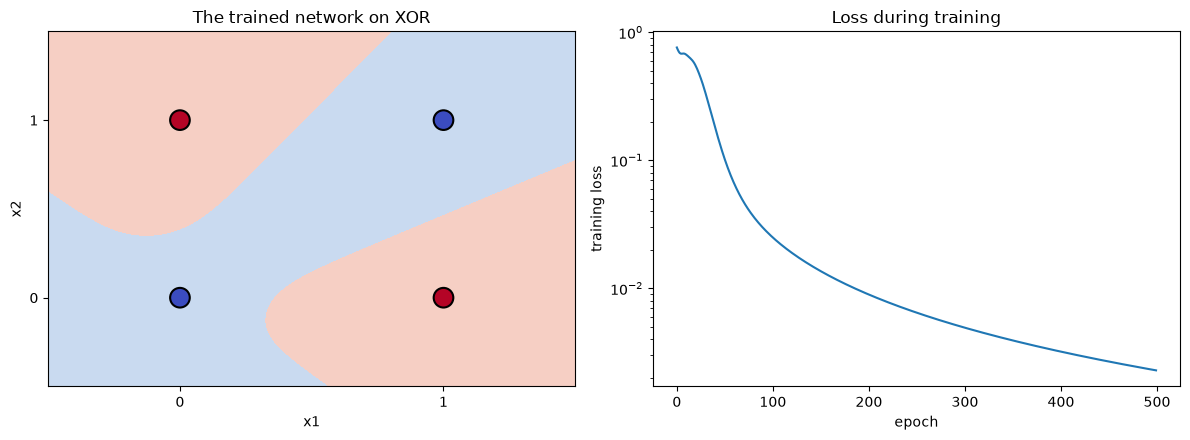

Loss after epoch 1: 0.760   after epoch 100: 0.025   after epoch 500: 0.00229


In [10]:
def network_probability(g):
    with torch.no_grad():
        return xor_model(torch.tensor(g, dtype=torch.float32)).numpy().ravel()


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
show_boundary(axes[0], network_probability, "The trained network on XOR")
axes[1].plot(history)
axes[1].set(xlabel="epoch", ylabel="training loss", title="Loss during training", yscale="log")
plt.tight_layout()
plt.show()
print(f"Loss after epoch 1: {history[0]:.3f}   after epoch 100: {history[99]:.3f}   after epoch 500: {history[-1]:.5f}")

The left plot is the same kind of picture as section 1. The network's boundary is not a line: two curved red regions hold the corners (0,1) and (1,0), and a blue band runs between them through (0,0) and (1,1). The loss on the right falls from 0.760 at epoch 1 to 0.025 by epoch 100 and 0.00229 at epoch 500. The vertical axis is logarithmic, so the curve is still falling slowly at the end.

Seventeen numbers are enough for XOR. Large networks have millions or billions, and the parameter count is worked out in the same way: weights plus biases, layer by layer.

## What to take away

- A single unit makes a straight-line decision. Stacking units adds nothing unless an activation follows each layer.
- Training is one loop: compute the loss, compute its gradient, move every weight a small step against the gradient. The learning rate sets the size of the step.
- Backpropagation computes the gradient for every weight in every layer; in PyTorch that is `loss.backward()`.
- Hidden layers learn new features from the inputs, and the output layer decides using those features. Counting parameters is simple arithmetic: for a dense layer, inputs × units + units.
- Session 7 runs this loop on a harder problem and shows how to read the loss curves to tell whether training is going well.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## One neuron

A neuron takes an input vector $x$, computes a weighted sum, and applies an activation $\phi$:

$$
z=w^\top x+b,\qquad a=\phi(z).
$$

The three activations in the plot are

$$
\sigma(z)=\frac{1}{1+e^{-z}},\qquad
\tanh(z)=\frac{e^{z}-e^{-z}}{e^{z}+e^{-z}},\qquad
\operatorname{ReLU}(z)=\max(0,z).
$$

## A full layer

A layer with $m$ neurons and $d$ inputs stores its weights as a matrix $W$ with $m$ rows and $d$ columns, and computes $a=\phi(Wx+b)$. A batch of $n$ examples is processed at once as a matrix product. The layer has $dm+m$ parameters.

## The loss

For a yes/no target $y$ and a predicted probability $\hat p$, the binary cross-entropy for one example is

$$
\ell(y,\hat p)=-\big[y\log\hat p+(1-y)\log(1-\hat p)\big].
$$

It is close to 0 when the model puts high probability on the right answer, and grows quickly when the model is confidently wrong. The training loss is its average over the training set.

## The gradient used in section 4

For one example, the unit computes $z=w^\top x+b$ and $p=\sigma(z)$. The derivative of the sigmoid is $\sigma'(z)=p(1-p)$, and it cancels against the logarithms in the loss, leaving

$$
\frac{\partial \ell}{\partial z}=p-y,\qquad
\frac{\partial \ell}{\partial w}=(p-y)\,x,\qquad
\frac{\partial \ell}{\partial b}=p-y .
$$

Averaging over the $n$ training examples gives $X^\top(p-y)/n$ for the weights and the mean of $p-y$ for the bias, the two expressions in `loss_and_gradient`. The gradient is large when the model is confidently wrong ($p$ far from $y$) and vanishes when it is right.

## Backpropagation and the optimiser

A training step has three parts. The **forward pass** computes the prediction layer by layer. **Backpropagation** uses the chain rule to find how the loss changes with each weight; for one weight, with $L$ the loss, $a=\phi(z)$ and $z=wx+b$,

$$
\frac{\partial L}{\partial w}=\frac{\partial L}{\partial a}\,\frac{\partial a}{\partial z}\,\frac{\partial z}{\partial w}.
$$

The **optimiser** then moves every parameter a small step against its gradient,

$$
\theta\leftarrow\theta-\eta\,\nabla_\theta L,
$$

where $\eta$ is the learning rate. Backpropagation only computes the gradient; deciding how to use it is the optimiser's job. Section 4 used exactly this rule. **Adam**, used in section 5, keeps for each parameter a running average of its recent gradients and of their squares, and steps by the first divided by the square root of the second. Weights with steady gradients take full-sized steps, and weights with noisy ones take smaller steps. Session 7 looks at what happens when these steps go well and badly.

## A network as a composition

A network with $L$ layers is a chain of functions,

$$
f(x)=f^{(L)}\big(f^{(L-1)}(\cdots f^{(1)}(x))\big),
$$

and later layers build on the features computed by earlier ones.